In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error 
from sklearn.model_selection import (KFold, cross_validate, cross_val_predict, train_test_split)
from scipy.stats import spearmanr
import shap
import time

TARGET = "prop_floodable_area_flooded" # "10cm_area"
GROUP_COL = None          # e.g. "catchment_id" / "cell_id" -- STRONGLY recommended if spatial/temporal autocorrelation
SEED = 42

from PrepDataFunctions import *
from ModelEvaluationFunctions import *

import sys, importlib
importlib.reload(sys.modules['ModelEvaluationFunctions'])
from ModelEvaluationFunctions import *

In [35]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl", 
                        remove_events_with_zero_flooding = False)
df = df[df['rainpeak_sm_day_before_onset'].notna()]

# Create a proportion floodable area flooded metric
df['peak_cell_floodable_area_km2'] = df['peak_cell_floodable_area_m2']*  0.000001
df['prop_floodable_area_flooded'] = (df['rainpeak_10cm_area']/df['peak_cell_floodable_area_km2'])*100

df['peak_share'] = df['peak_share'] * 100
df['rainfall_before_peak_pct'] = df['rainfall_before_peak'] / df['rainpeak_total_precip'] * 100
df['rainfall_after_peak_pct'] = df['rainfall_after_peak'] / df['rainpeak_total_precip'] * 100
# df['rainfall_before_peak_pct'] + df['rainfall_after_peak_pct'] + df['peak_share']

In [24]:
# --- 2. split events by how much rain falls outside the peak step ---
subset_early["peak_class"] = pd.cut(subset_early["peak_share"], [0, 0.5, 0.8, 1.0], 
                                    labels=["spread", "mixed", "peak-dominated"], include_lowest=True)
peak_dominated_events = subset_early[subset_early['peak_class'] == 'peak-dominated']

In [12]:
# for event_type in ['mixed', 'spread', 'peak-dominated', ]:
#     print(event_type)
#     subset_early = subset_early[subset_early['modality'] =='unimodal']
#     df = subset_early[subset_early['peak_class'] == event_type ]
    
#     rf = RandomForestRegressor(n_estimators=800, min_samples_leaf = 2, max_depth=16,max_samples = None, max_features = 1.0, 
#                            random_state=42)
#     lr = LinearRegression()
    
#     X = df[my_vars]
#     y = df['10cm_area']
    
#     all_variables_r2_lr = cross_val_score(lr, X, y, cv=cv_parameters, scoring='r2').mean()
#     print(f"Full model R²: {all_variables_r2_lr:.4f}")

#     all_variables_r2_rf = cross_val_score(rf, X, y, cv=cv_parameters, scoring='r2').mean()
#     print(f"Full model R²: {all_variables_r2_rf:.4f}")

69959
54997
period
1980-2000     3351
2020-2040    13041
2060-2080    17398
Name: n_events, dtype: int64 

period                          1980-2000  2020-2040  2060-2080
d50                      count    3351.00   13041.00   17398.00
                         mean       41.82      43.61      43.27
                         std        31.71      31.69      31.13
                         min         0.00       0.00       0.00
                         10%         3.24       4.20       4.33
                         50%        40.09      42.48      41.31
                         90%        85.87      87.37      86.98
                         max        98.72      99.22      99.31
peak_position_ratio      count    3351.00   13041.00   17398.00
                         mean        0.46       0.48       0.48
                         std         0.33       0.33       0.32
                         min         0.00       0.00       0.00
                         10%         0.05       0.06       0.

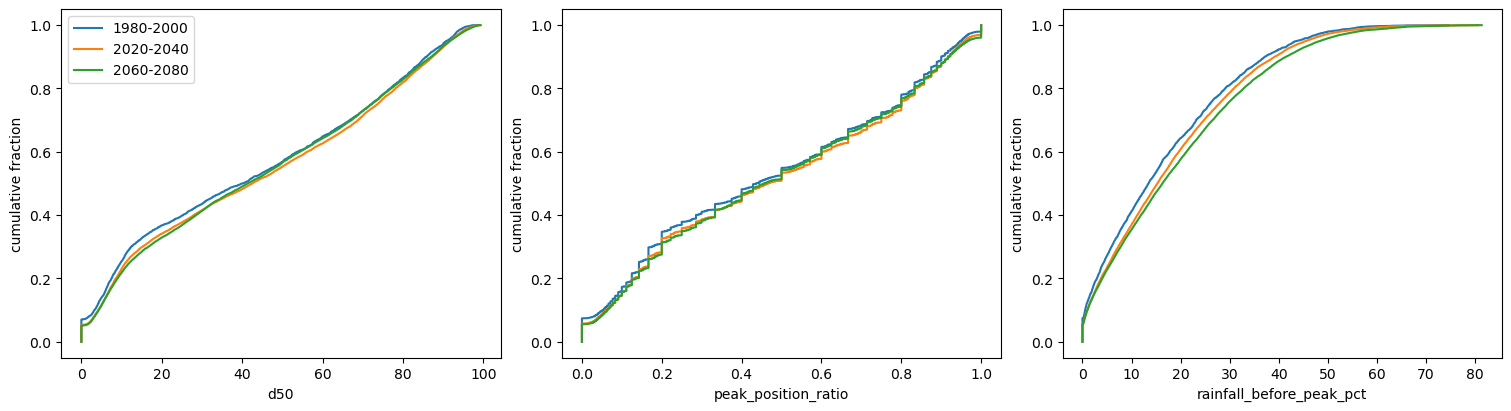

   period                   metric  median_change  ci_lo  ci_hi
2020-2040                      d50           2.30  -0.67   7.12
2020-2040      peak_position_ratio           0.03  -0.01   0.07
2020-2040 rainfall_before_peak_pct           1.77   0.75   2.65
2060-2080                      d50           1.20  -1.68   5.92
2060-2080      peak_position_ratio           0.02  -0.02   0.06
2060-2080 rainfall_before_peak_pct           2.82   1.82   3.75

Median by dur_band and period
d50
period    1980-2000  2020-2040  2060-2080
dur_band                                 
short         26.43      29.51      31.44
mid           47.65      46.50      44.51
long          50.87      52.69      49.38
peak_position_ratio
period    1980-2000  2020-2040  2060-2080
dur_band                                 
short          0.33       0.38       0.40
mid            0.50       0.50       0.50
long           0.53       0.55       0.52
rainfall_before_peak_pct
period    1980-2000  2020-2040  2060-2080
dur_band  

In [39]:
import statsmodels.formula.api as smf

# --- edit these ---
METRICS = ["d50", "peak_position_ratio", "rainfall_before_peak_pct"]
PERIODS = {"1980-2000": (1980, 2000), "2020-2040": (2020, 2040), "2060-2080": (2060, 2080)}
BASE = "1980-2000"
DUR, TOT = "length_of_active_rain", "total_acc"
MIN_STEPS = 6
MODALITIES = ['unimodal']
# ------------------

d = df[df[DUR] >= MIN_STEPS].copy()
print(len(d))
d = d[d['modality'].isin(MODALITIES)].copy()
print(len(d))

d["period"] = None
for name, (a, b) in PERIODS.items():
    d.loc[d.start_year.between(a, b), "period"] = name
d = d.dropna(subset=["period"])

# 1) counts and summary stats per period
print(d.groupby("period").size().rename("n_events"), "\n")
print(d.groupby("period")[METRICS].describe(percentiles=[.1, .5, .9]).T.round(2))

# 2) ECDFs per metric
fig, axes = plt.subplots(1, len(METRICS), figsize=(5 * len(METRICS), 4), constrained_layout=True)
for ax, m in zip(axes, METRICS):
    for p in PERIODS:
        x = np.sort(d.loc[d.period == p, m].dropna())
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), label=p)
    ax.set(xlabel=m, ylabel="cumulative fraction")
axes[0].legend()
plt.show()

# 3) change in median vs baseline, bootstrapped by year (blocks = years)
rng = np.random.default_rng(0)
def boot_diff(m, period, n_boot=1000):
    g0 = d[d.period == BASE].groupby("start_year")[m].apply(np.array)
    g1 = d[d.period == period].groupby("start_year")[m].apply(np.array)
    out = []
    for _ in range(n_boot):
        s0 = np.concatenate(g0.sample(len(g0), replace=True, random_state=rng.integers(1e9)).values)
        s1 = np.concatenate(g1.sample(len(g1), replace=True, random_state=rng.integers(1e9)).values)
        out.append(np.nanmedian(s1) - np.nanmedian(s0))
    return np.percentile(out, [2.5, 50, 97.5])

rows = []
for p in PERIODS:
    if p == BASE: continue
    for m in METRICS:
        lo, mid, hi = boot_diff(m, p)
        rows.append({"period": p, "metric": m, "median_change": mid, "ci_lo": lo, "ci_hi": hi})
print(pd.DataFrame(rows).round(2).to_string(index=False))

# 4) is the change just due to event size? same comparison within bands
d["dur_band"] = pd.qcut(d[DUR], 3, labels=["short", "mid", "long"], duplicates="drop")
d["tot_band"] = pd.qcut(d[TOT], 3, labels=["low", "mid", "high"])
for band in ["dur_band", "tot_band"]:
    print(f"\nMedian by {band} and period")
    for m in METRICS:
        print(m)
        print(d.pivot_table(index=band, columns="period", values=m,
                            aggfunc="median", observed=True).round(2))

# 5) adjusted shift: regression of metric on period, controlling for size
for m in METRICS:
    fit = smf.quantreg(f"{m} ~ C(period, Treatment('{BASE}')) + np.log({TOT}) + np.log({DUR})",
                       d.dropna(subset=[m])).fit(q=0.5)
    print(f"\n{m} (median regression)")
    print(fit.summary().tables[1])

In [40]:
d["dur_band"] = pd.qcut(d[DUR], 3, labels=["short", "mid", "long"], duplicates="drop")
d["tot_band"] = pd.qcut(d[TOT], 3, labels=["low", "mid", "high"])
for band in ["dur_band", "tot_band"]:
    print(f"\nMedian by {band} and period")
    for m in ['d50']:
        print(m)
        print(d.pivot_table(index=band, columns="period", values=m,
                            aggfunc="median", observed=True).round(2))


Median by dur_band and period
d50
period    1980-2000  2020-2040  2060-2080
dur_band                                 
short         26.43      29.51      31.44
mid           47.65      46.50      44.51
long          50.87      52.69      49.38

Median by tot_band and period
d50
period    1980-2000  2020-2040  2060-2080
tot_band                                 
low           33.21      39.32      36.04
mid           42.21      42.74      41.74
high          41.98      44.48      43.67


In [23]:
d["dur_band"] = pd.qcut(d[DUR], 3, labels=["short", "mid", "long"], duplicates="drop")
d["tot_band"] = pd.qcut(d[TOT], 3, labels=["low", "mid", "high"])
for band in ["dur_band", "tot_band"]:
    print(f"\nMedian by {band} and period")
    for m in ['d50']:
        print(m)
        print(d.pivot_table(index=band, columns="period", values=m,
                            aggfunc="median", observed=True).round(2))


Median by dur_band and period
d50
period    1980-2000  2020-2040  2060-2080
dur_band                                 
short         28.63      31.02      32.77
mid           47.55      48.01      45.19
long          49.23      50.66      49.10

Median by tot_band and period
d50
period    1980-2000  2020-2040  2060-2080
tot_band                                 
low           35.60      39.98      37.57
mid           41.42      43.81      41.72
high          41.96      44.74      45.84
